# Análise Exploratória de Dados — SINASC 2024

## Trabalho Final Integrado

- Curso: Engenharia de Software
- Responsável: Marcus Mikael Rodrigues Vieira
- Frente: Inteligência Artificial
- Base de dados: SINASC 2024
- Contexto 4 — Variante A: Risco de baixo peso ao nascer

## Objetivo

Compreender a estrutura, a qualidade e as características
da base de dados antes do desenvolvimento do modelo
de aprendizado de máquina.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [7]:
# Identificar a raiz do projeto
raiz = Path.cwd()

while not (raiz / ".git").exists():
    if raiz == raiz.parent:
        raise FileNotFoundError("Raiz do projeto não encontrada.")
    raiz = raiz.parent

# Caminho do arquivo CSV
caminho = raiz / "data" / "raw" / "DNRE2024.csv"

print("Caminho:", caminho)
print("Arquivo encontrado:", caminho.exists())

Caminho: d:\Trabalho Final - IAGOVBACKEND\sistema-sinasc\sinasc-risco-peso\data\raw\DNRE2024.csv
Arquivo encontrado: True


In [8]:
# carregar os dados
df = pd.read_csv(
    caminho,
    sep=",",
    encoding="utf-8",
    low_memory=False
)

print("Base carregada com sucesso!")
print("Quantidade de registros:", df.shape[0])
print("Quantidade de colunas:", df.shape[1])

Base carregada com sucesso!
Quantidade de registros: 120786
Quantidade de colunas: 37


In [9]:
print("Colunas da base de dados:\n")

for numero, coluna in enumerate(df.columns, start=1):
    print(f"{numero}. {coluna}")

Colunas da base de dados:

1. LOCNASC
2. CODMUNNASC
3. FxEtPartur
4. RACACORMAE
5. CODUFNATU
6. ESTCIVMAE
7. ESCMAE
8. ESCMAE2010
9. SERIESCMAE
10. CODOCUPMAE
11. CODMUNRES
12. CODPAISRES
13. QTDGESTANT
14. QTDPARTNOR
15. QTDPARTCES
16. QTDFILVIVO
17. QTDFILMORT
18. SEMAGESTAC
19. TPMETESTIM
20. CONSPRENAT
21. MESPRENAT
22. GRAVIDEZ
23. TPAPRESENT
24. STTRABPART
25. PARTO
26. STCESPARTO
27. TPNASCASSI
28. DTNASC2
29. SEXO
30. APGAR1
31. APGAR5
32. PESO
33. IDANOMAL
34. FaixaEtPai
35. RETROALIM
36. TPROBSON
37. STDNNOVA


## Análise dos tipos de dados

Identificação dos tipos de dados e da quantidade de
valores preenchidos em cada atributo da base SINASC.

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 120786 entries, 0 to 120785
Data columns (total 37 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   LOCNASC     120786 non-null  int64  
 1   CODMUNNASC  120786 non-null  int64  
 2   FxEtPartur  120786 non-null  str    
 3   RACACORMAE  120748 non-null  float64
 4   CODUFNATU   115092 non-null  float64
 5   ESTCIVMAE   120711 non-null  float64
 6   ESCMAE      120779 non-null  float64
 7   ESCMAE2010  120778 non-null  float64
 8   SERIESCMAE  78040 non-null   float64
 9   CODOCUPMAE  119572 non-null  float64
 10  CODMUNRES   120786 non-null  int64  
 11  CODPAISRES  120786 non-null  int64  
 12  QTDGESTANT  120767 non-null  float64
 13  QTDPARTNOR  120763 non-null  float64
 14  QTDPARTCES  120768 non-null  float64
 15  QTDFILVIVO  120762 non-null  float64
 16  QTDFILMORT  120748 non-null  float64
 17  SEMAGESTAC  120766 non-null  float64
 18  TPMETESTIM  97854 non-null   float64
 19  CONSPRENAT  1

## Análise de valores ausentes

Identificação da quantidade e do percentual de dados
ausentes em cada atributo, auxiliando nas decisões
de pré-processamento.

In [11]:
dados_ausentes = pd.DataFrame({
    "Quantidade": df.isnull().sum(),
    "Percentual (%)": (df.isnull().mean() * 100).round(2)
})

dados_ausentes = dados_ausentes.sort_values(
    by="Quantidade",
    ascending=False
)

dados_ausentes

,Quantidade,Percentual (%)
FaixaEtPai,89816,74.36
STCESPARTO,56947,47.15
SERIESCMAE,42746,35.39
TPMETESTIM,22932,18.99
CODUFNATU,5694,4.71
CODOCUPMAE,1214,1.01
MESPRENAT,911,0.75
APGAR1,344,0.28
APGAR5,341,0.28
IDANOMAL,76,0.06


## Análise de registros duplicados

Verificação da existência de linhas completamente
idênticas na base de dados.

In [12]:
duplicados = df.duplicated().sum()

print("Quantidade de registros duplicados:", duplicados)

Quantidade de registros duplicados: 5


## Análise do peso ao nascer

A coluna PESO representa o peso do recém-nascido
em gramas e será utilizada para construir a
variável-alvo do modelo de classificação.

In [13]:
print("Estatísticas do peso ao nascer:")

display(df["PESO"].describe())

print("\nQuantidade de valores ausentes:")
print(df["PESO"].isnull().sum())

print("\nTipo de dado:")
print(df["PESO"].dtype)

Estatísticas do peso ao nascer:


count    120785.000000
mean       3122.272956
std         557.511095
min         125.000000
25%        2850.000000
50%        3170.000000
75%        3470.000000
max        5595.000000
Name: PESO, dtype: float64


Quantidade de valores ausentes:
1

Tipo de dado:
float64


## Observações iniciais sobre a qualidade dos dados

A base SINASC 2024 possui 120.786 registros e 37 atributos.

Foram identificados:

- 5 registros com atributos completamente idênticos;
- 1 registro sem informação de peso ao nascer;
- Atributos com elevado percentual de valores ausentes;
- Atributos numéricos que representam categorias;
- Necessidade de investigar valores extremos e códigos
  utilizados para representar informações ignoradas.

Os registros idênticos não serão removidos automaticamente,
pois não existe um identificador único que permita confirmar
que representam o mesmo nascimento.

## Verificação da qualidade da variável-alvo

Identificação de valores ausentes, não positivos e
pesos extremos na coluna PESO.

In [14]:
print("Pesos ausentes:", df["PESO"].isnull().sum())

print("Pesos menores ou iguais a zero:",
      (df["PESO"] <= 0).sum())

print("Pesos inferiores a 500 g:",
      (df["PESO"] < 500).sum())

print("Pesos superiores a 5000 g:",
      (df["PESO"] > 5000).sum())

print("Possíveis códigos de peso ignorado:",
      df["PESO"].isin([9999]).sum())

Pesos ausentes: 1
Pesos menores ou iguais a zero: 0
Pesos inferiores a 500 g: 136
Pesos superiores a 5000 g: 24
Possíveis códigos de peso ignorado: 0


## Distribuição da variável-alvo

A variável baixo_peso será utilizada para representar
o problema de classificação binária:

- Classe 0: peso ao nascer igual ou superior a 2500 g.
- Classe 1: peso ao nascer inferior a 2500 g.

Para esta análise exploratória, serão considerados apenas
os registros com peso preenchido e positivo, excluindo
possíveis códigos de peso ignorado.

In [15]:

df_eda = df[
    df["PESO"].notna()
    & (df["PESO"] > 0)
    & (df["PESO"] != 9999)
].copy()

# Criar a variável-alvo
df_eda["baixo_peso"] = (
    df_eda["PESO"] < 2500
).astype(int)

print("Total de registros originais:", len(df))
print("Total de registros considerados:", len(df_eda))
print("Registros excluídos:", len(df) - len(df_eda))

distribuicao = pd.DataFrame({
    "Quantidade": df_eda["baixo_peso"].value_counts().sort_index(),
    "Percentual (%)": (
        df_eda["baixo_peso"]
        .value_counts(normalize=True)
        .sort_index() * 100
    ).round(2)
})

display(distribuicao)

Total de registros originais: 120786
Total de registros considerados: 120785
Registros excluídos: 1


,Quantidade,Percentual (%)
baixo_peso,,
0,108313,89.67
1,12472,10.33


## Visualização da distribuição do peso ao nascer

Histograma utilizado para compreender a distribuição
dos pesos e visualizar o limite de 2500 gramas que
define a classe de baixo peso.

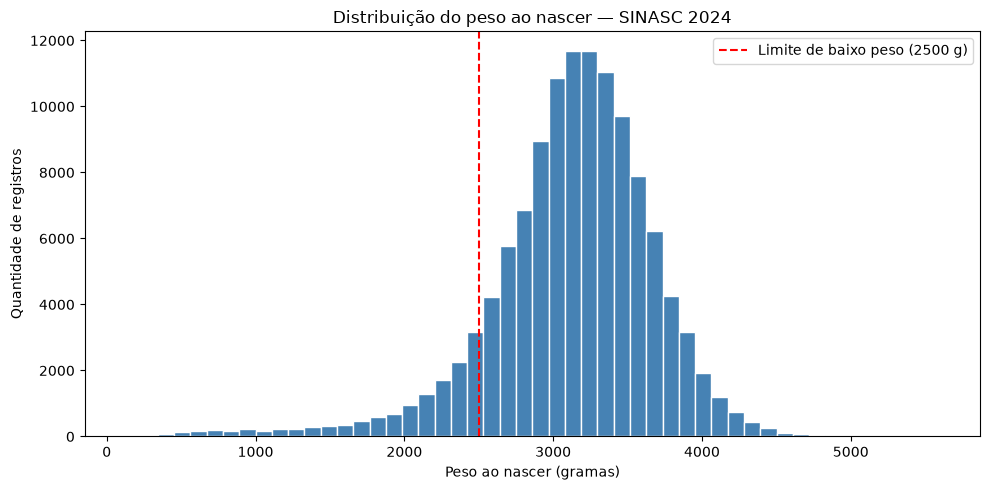

In [16]:
plt.figure(figsize=(10, 5))

plt.hist(
    df_eda["PESO"],
    bins=50,
    color="steelblue",
    edgecolor="white"
)

plt.axvline(
    x=2500,
    color="red",
    linestyle="--",
    label="Limite de baixo peso (2500 g)"
)

plt.title("Distribuição do peso ao nascer — SINASC 2024")
plt.xlabel("Peso ao nascer (gramas)")
plt.ylabel("Quantidade de registros")
plt.legend()
plt.tight_layout()
plt.show()

## Análise do desbalanceamento das classes

Visualização da quantidade de registros de cada classe
para identificar possíveis problemas de desbalanceamento.

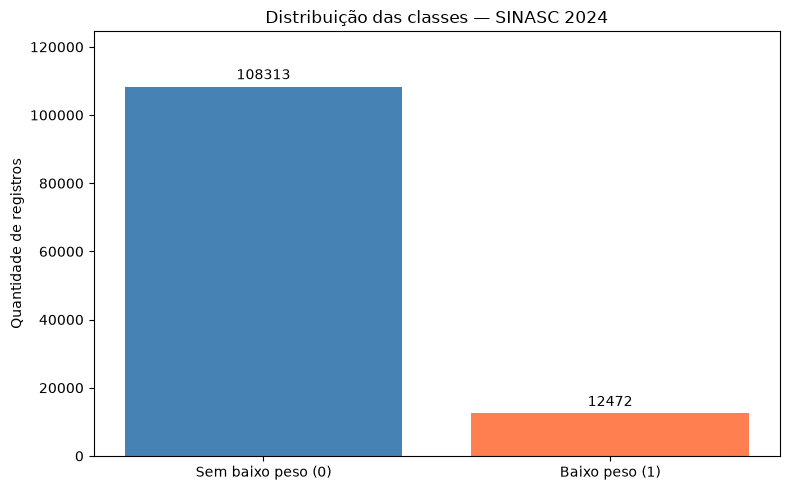

In [17]:
classes = df_eda["baixo_peso"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

barras = plt.bar(
    ["Sem baixo peso (0)", "Baixo peso (1)"],
    classes.values,
    color=["steelblue", "coral"]
)

plt.bar_label(barras, padding=3)

plt.title("Distribuição das classes — SINASC 2024")
plt.ylabel("Quantidade de registros")
plt.ylim(0, classes.max() * 1.15)
plt.tight_layout()
plt.show()

## Interpretação do desbalanceamento

A base considerada nesta análise apresenta 120.785
registros válidos, distribuídos da seguinte forma:

- Classe 0: 108.313 registros (89,67%).
- Classe 1: 12.472 registros (10,33%).

Existe um desbalanceamento significativo entre as classes. Um modelo que classificasse todos os registros como
classe 0 obteria uma acurácia de aproximadamente 89,67%,
mas não identificaria nenhum caso de baixo peso.

Por esse motivo, a acurácia não será utilizada como
métrica principal de avaliação. O Recall da classe positiva será priorizado, acompanhado
de Precision, F2-score, PR-AUC e matriz de confusão.


## Conclusão da análise exploratória

A análise exploratória da base SINASC 2024 permitiu
identificar as características iniciais dos dados e
orientar as próximas etapas do projeto.

### Principais resultados

- 120.786 registros originais.
- 37 atributos disponíveis.
- 5 linhas completamente idênticas.
- 1 registro sem informação de peso.
- 120.785 registros válidos para análise do alvo.
- 136 registros com peso inferior a 500 gramas.
- 24 registros com peso superior a 5000 gramas.
- Desbalanceamento significativo entre as classes.
- Presença de atributos com valores ausentes.

### Decisões iniciais

- Preservar a base de dados original.
- Excluir registros sem informação da variável-alvo.
- Manter provisoriamente os registros com pesos extremos.
- Não remover automaticamente registros idênticos.
- Investigar códigos que representam dados ignorados.
- Remover atributos com vazamento de dados.
- Priorizar métricas adequadas ao desbalanceamento.

### Próximas etapas

- Definição dos atributos preditores.
- Identificação e remoção de vazamento de dados.
- Separação dos conjuntos de treino e teste.
- Construção do pipeline de pré-processamento.
- Comparação dos modelos de classificação.
- Avaliação e exportação do modelo selecionado.